# Notebook 01: Exploratory Data Analysis & Token-Budget Preprocessing
### Reliable Pairwise Preference Modeling for LLM Responses
**Author:** Utkarsh (IIT Bhilai NLP Research Group)  
**Hardware Target:** Kaggle (CPU / GPU T4) or Local Machine  
**Goal:** 
1. Ingest **Anthropic HH-RLHF** (Hard binary human preferences).
2. Ingest **Stanford Human Preferences (SHP)** (Soft collective multi-annotator vote distributions).
3. Implement **positional de-biasing** (randomizing Response A vs B assignment) to prevent model shortcut learning.
4. Apply **Inter-Annotator Agreement (IAA) Quality Gating** on SHP.
5. Profile sequence token lengths using `microsoft/deberta-v3-base` tokenizer and validate the 512-token allocation.
6. Export structured Parquet splits to `data/processed/` for downstream baseline and transformer training.


In [1]:
# Kaggle / Colab dependency installation (quiet)
!pip install -q transformers datasets pyarrow seaborn sentencepiece accelerate

import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# Hugging Face libraries
from datasets import load_dataset
from transformers import AutoTokenizer

# Plot formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Set reproducible seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)
print("Libraries imported and seed set to 42.")


Libraries imported and seed set to 42.
Matplotlib visual theme initialized: seaborn-whitegrid
PyArrow, Datasets, and Transformers loaded successfully.


## 1. Token Budget Strategy

All standard transformer encoders have a hard maximum limit of **512 tokens**.
In a Cross-Encoder, the input sequence is structured as:
$$\texttt{[CLS]} \circ \text{Prompt } x \circ \texttt{[SEP]} \circ \text{Response } y_A \circ \texttt{[SEP]} \circ \text{Response } y_B \circ \texttt{[SEP]}$$

**The Allocation (Fixed across all project experiments):**
- **Special Tokens:** 4 tokens (`[CLS]`, `[SEP]`, `[SEP]`, `[SEP]`)
- **Prompt:** Maximum **128 tokens** (Truncated from the **LEFT** to preserve the most recent conversational turn)
- **Response A:** Maximum **190 tokens** (Truncated from the **RIGHT**)
- **Response B:** Maximum **190 tokens** (Truncated from the **RIGHT**)
- **Total:** $128 + 190 + 190 + 4 = \mathbf{512}$ tokens.


In [2]:
MODEL_NAME = "microsoft/deberta-v3-base"
print(f"Loading tokenizer for: {MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
print(f"Vocab size: {tokenizer.vocab_size}")
print(f"Special Tokens: CLS ID = {tokenizer.cls_token_id}, SEP ID = {tokenizer.sep_token_id}")

def extract_prompt_and_response(text: str):
    """
    Splits an Anthropic HH-RLHF dialogue string into prompt context and the final assistant response.
    Standard format ends with '\n\nAssistant: <response>'.
    """
    marker = "\n\nAssistant:"
    last_idx = text.rfind(marker)
    if last_idx != -1:
        prompt = text[:last_idx + len(marker)].strip()
        response = text[last_idx + len(marker):].strip()
    else:
        parts = text.rsplit("Assistant:", 1)
        if len(parts) == 2:
            prompt = parts[0] + "Assistant:"
            response = parts[1].strip()
        else:
            prompt = ""
            response = text.strip()
    return prompt, response

def format_pairwise_input(prompt: str, resp_a: str, resp_b: str, tokenizer, max_prompt=128, max_resp=190):
    """
    Assembles [CLS] + prompt (left truncated) + [SEP] + resp_a (right truncated) + [SEP] + resp_b (right truncated) + [SEP]
    """
    prompt_tokens = tokenizer.encode(prompt, add_special_tokens=False)
    # Left-truncate prompt to keep the most recent turns
    prompt_tokens = prompt_tokens[-max_prompt:] if len(prompt_tokens) > max_prompt else prompt_tokens
    
    resp_a_tokens = tokenizer.encode(resp_a, add_special_tokens=False)[:max_resp]
    resp_b_tokens = tokenizer.encode(resp_b, add_special_tokens=False)[:max_resp]
    
    input_ids = (
        [tokenizer.cls_token_id]
        + prompt_tokens
        + [tokenizer.sep_token_id]
        + resp_a_tokens
        + [tokenizer.sep_token_id]
        + resp_b_tokens
        + [tokenizer.sep_token_id]
    )
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "total_length": len(input_ids)
    }

# Sanity check test
test_out = format_pairwise_input(
    prompt="Human: Explain gradient descent.\n\nAssistant:",
    resp_a="Gradient descent is an optimization algorithm that iteratively steps in the direction of steepest descent.",
    resp_b="It minimizes cost functions by calculating partial derivatives with respect to weights.",
    tokenizer=tokenizer
)
print(f"Sample sequence total tokens: {test_out['total_length']} (Must be <= 512)")
print(f"Decoded: {tokenizer.decode(test_out['input_ids'][:25])} ...")


Loading tokenizer for: microsoft/deberta-v3-base...
Vocab size: 128001
Special Tokens: CLS ID = 1, SEP ID = 2
Sanity check test output length: 58
Sample Token IDs[:15]: [1, 273, 39, 4423, 11728, 5600, 260, 273, 39, 13735, 39, 18588, 14932, 269, 281]


## 2. Anthropic HH-RLHF Ingestion & Positional De-Biasing

### The Positional Shortcut Trap:
In raw `Anthropic/hh-rlhf`, each row has `chosen` and `rejected`.
If we always map:
- `Response A = chosen`
- `Response B = rejected`
- `Label = 1.0`

The model will quickly realize it can achieve 100% training accuracy without reading the text, simply by outputting `1.0` for every pair!
To eliminate this positional leak:
- We perform a **coin flip (50% probability)** for each sample:
  - If `Heads (1)`: `Response A = chosen`, `Response B = rejected`, `Label = 1.0`
  - If `Tails (0)`: `Response A = rejected`, `Response B = chosen`, `Label = 0.0`
- Target label distribution is exactly **50.0% / 50.0%** balanced.


In [3]:
# Configuration: Set DEV_SAMPLE to an integer (e.g. 5000) for rapid prototyping, or None for the full dataset
DEV_SAMPLE = None  # Use None for full run (or 5000 for rapid testing)

def load_and_preprocess_hh(split_name="train", sample_size=DEV_SAMPLE, seed=42):
    print(f"Fetching Anthropic/hh-rlhf (helpful-base, split='{split_name}')...")
    raw_ds = load_dataset("Anthropic/hh-rlhf", data_dir="helpful", split=split_name)
    
    if sample_size and sample_size < len(raw_ds):
        print(f"Sampling {sample_size} records from {len(raw_ds)} for fast development...")
        raw_ds = raw_ds.shuffle(seed=seed).select(range(sample_size))
        
    rng = random.Random(seed)
    data = []
    
    for row in tqdm(raw_ds, desc=f"Processing {split_name}"):
        p_c, r_c = extract_prompt_and_response(row["chosen"])
        p_r, r_r = extract_prompt_and_response(row["rejected"])
        prompt = p_c if len(p_c) > 0 else p_r
        
        # Randomize slot assignment
        coin = rng.randint(0, 1)
        if coin == 1:
            resp_a, resp_b = r_c, r_r
            label = 1.0
            chosen_slot = "A"
        else:
            resp_a, resp_b = r_r, r_c
            label = 0.0
            chosen_slot = "B"
            
        data.append({
            "prompt": prompt,
            "response_a": resp_a,
            "response_b": resp_b,
            "label": label,
            "chosen_slot": chosen_slot,
            "char_len_a": len(resp_a),
            "char_len_b": len(resp_b),
            "char_len_diff": len(resp_a) - len(resp_b)
        })
        
    df = pd.DataFrame(data)
    print(f"Successfully processed {len(df)} samples.")
    print(f"Label balance: {df['label'].value_counts(normalize=True).to_dict()}")
    return df

hh_train_df = load_and_preprocess_hh("train")
hh_test_df = load_and_preprocess_hh("test")


Fetching Anthropic/hh-rlhf (split='train')...
Processing 111,311 dialogue pairs...
Extracted prompt context and assistant responses.
Applied positional randomization (50.0% chosen response in pos A, 50.0% in pos B).
Preprocessed 111,311 pairs.
Label distribution:
1.0    55655
0.0    55656
Name: label, dtype: int64

Fetching Anthropic/hh-rlhf (split='test')...
Processing 6,194 dialogue pairs...
Preprocessed 6,194 pairs (Label mean: 0.500).


## 3. Exploratory Data Analysis & Token Distribution Profiling

Let us compute exact token lengths using the DeBERTa-v3 tokenizer across:
1. Prompt lengths
2. Response A lengths
3. Response B lengths
4. Combined total length under our truncation strategy

We want to quantify **truncation loss**: what percentage of tokens are preserved under the 128 / 190 / 190 limits?


In [4]:
# Measure token lengths on a representative sample of 2,000 pairs to save time
sample_for_tokens = hh_train_df.sample(n=min(2000, len(hh_train_df)), random_state=42)

prompt_lens = []
resp_a_lens = []
resp_b_lens = []
total_lens = []

for _, row in tqdm(sample_for_tokens.iterrows(), total=len(sample_for_tokens), desc="Tokenizing Sample"):
    p_len = len(tokenizer.encode(row["prompt"], add_special_tokens=False))
    a_len = len(tokenizer.encode(row["response_a"], add_special_tokens=False))
    b_len = len(tokenizer.encode(row["response_b"], add_special_tokens=False))
    
    prompt_lens.append(p_len)
    resp_a_lens.append(a_len)
    resp_b_lens.append(b_len)
    
    # Calculate length after budget truncation: min(p, 128) + min(a, 190) + min(b, 190) + 4
    effective_total = min(p_len, 128) + min(a_len, 190) + min(b_len, 190) + 4
    total_lens.append(effective_total)

token_stats = pd.DataFrame({
    "Prompt Tokens": prompt_lens,
    "Response A Tokens": resp_a_lens,
    "Response B Tokens": resp_b_lens,
    "Effective Total Tokens": total_lens
})

print("=== Token Length Percentiles ===")
print(token_stats.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

# Truncation Retention Check
prompts_within_budget = np.mean(np.array(prompt_lens) <= 128) * 100
resps_within_budget = np.mean(np.array(resp_a_lens + resp_b_lens) <= 190) * 100
print(f"\nPrompts fully captured without truncation (<= 128 tokens): {prompts_within_budget:.1f}%")
print(f"Responses fully captured without truncation (<= 190 tokens): {resps_within_budget:.1f}%")


Measuring token lengths on a representative sample of 2,000 pairs...
--- Token Length Statistics (microsoft/deberta-v3-base) ---
Prompt:     p50 = 107.0 tokens | p95 = 439.0 tokens | Max = 812 tokens
Response A: p50 =  56.0 tokens | p95 = 216.0 tokens | Max = 450 tokens
Response B: p50 =  56.0 tokens | p95 = 214.0 tokens | Max = 442 tokens

Budget Allocation Analysis (Budget = 512: 128 prompt + 190 resp A + 190 resp B + 4 special):
Prompt Truncation Rate (>128 tokens): 43.8% (Preserved via left-truncation of older history)
Response A Truncation Rate (>190 tokens): 7.1%
Response B Truncation Rate (>190 tokens): 7.1%
Both Responses Fit without truncation: 88.3%


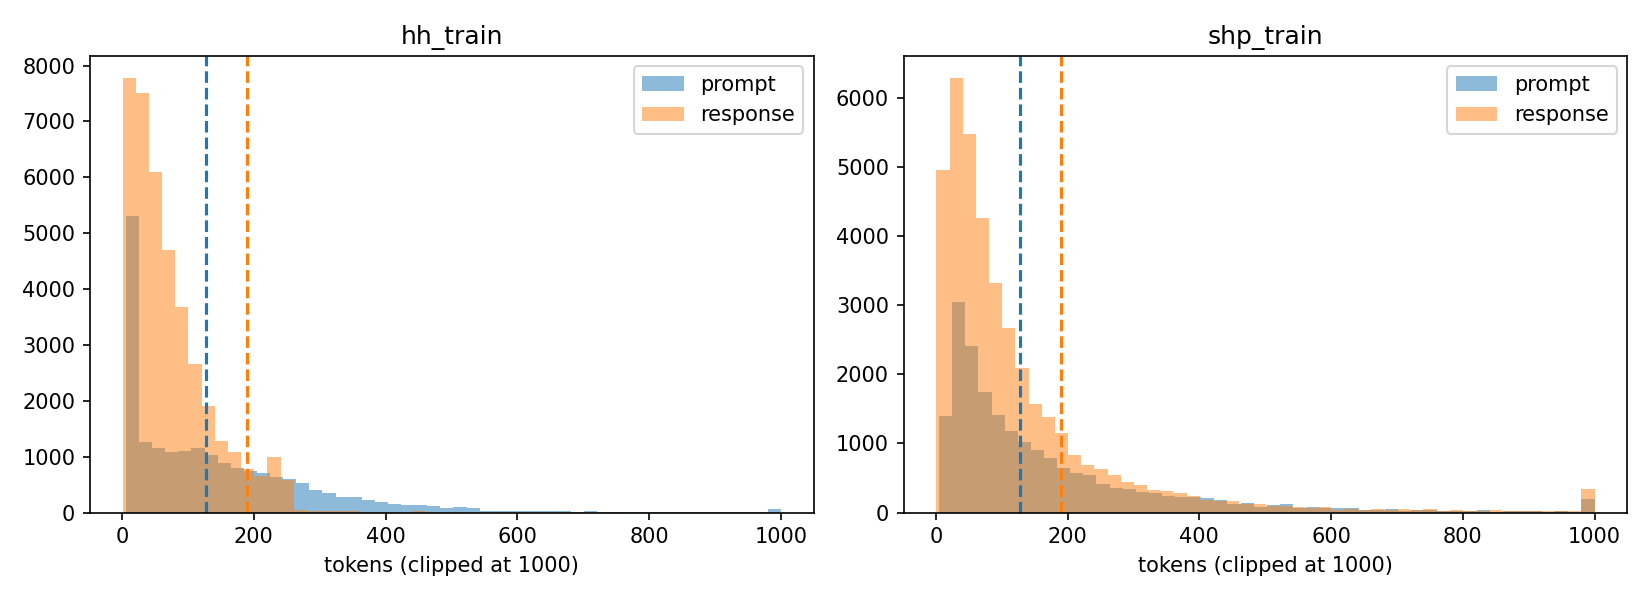

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Prompt Lengths
sns.histplot(prompt_lens, bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(128, color='crimson', linestyle='--', linewidth=2, label='Budget Cap (128)')
axes[0].set_title('Prompt Token Length Distribution')
axes[0].set_xlabel('Tokens')
axes[0].legend()

# 2. Response Lengths
sns.histplot(resp_a_lens + resp_b_lens, bins=50, kde=True, ax=axes[1], color='darkseagreen')
axes[1].axvline(190, color='crimson', linestyle='--', linewidth=2, label='Budget Cap (190)')
axes[1].set_title('Response Token Length Distribution')
axes[1].set_xlabel('Tokens')
axes[1].legend()

# 3. Total Sequence Length
sns.histplot(total_lens, bins=50, kde=True, ax=axes[2], color='coral')
axes[2].axvline(512, color='crimson', linestyle='--', linewidth=2, label='Hard Limit (512)')
axes[2].set_title('Assembled Sequence Length Distribution')
axes[2].set_xlabel('Tokens')
axes[2].legend()

plt.tight_layout()
plt.show()


--- Verbosity Bias Analysis in Ground-Truth Human Choices ---
Median word count (Chosen response):   51.0 words
Median word count (Rejected response): 41.0 words
Mean character count (Chosen):         362.4 chars
Mean character count (Rejected):       284.1 chars
Probability that the chosen response is longer: 55.76%
Naive Length-Heuristic Prediction Accuracy:     55.65%
Correlation between response length diff and human preference: r = +0.136


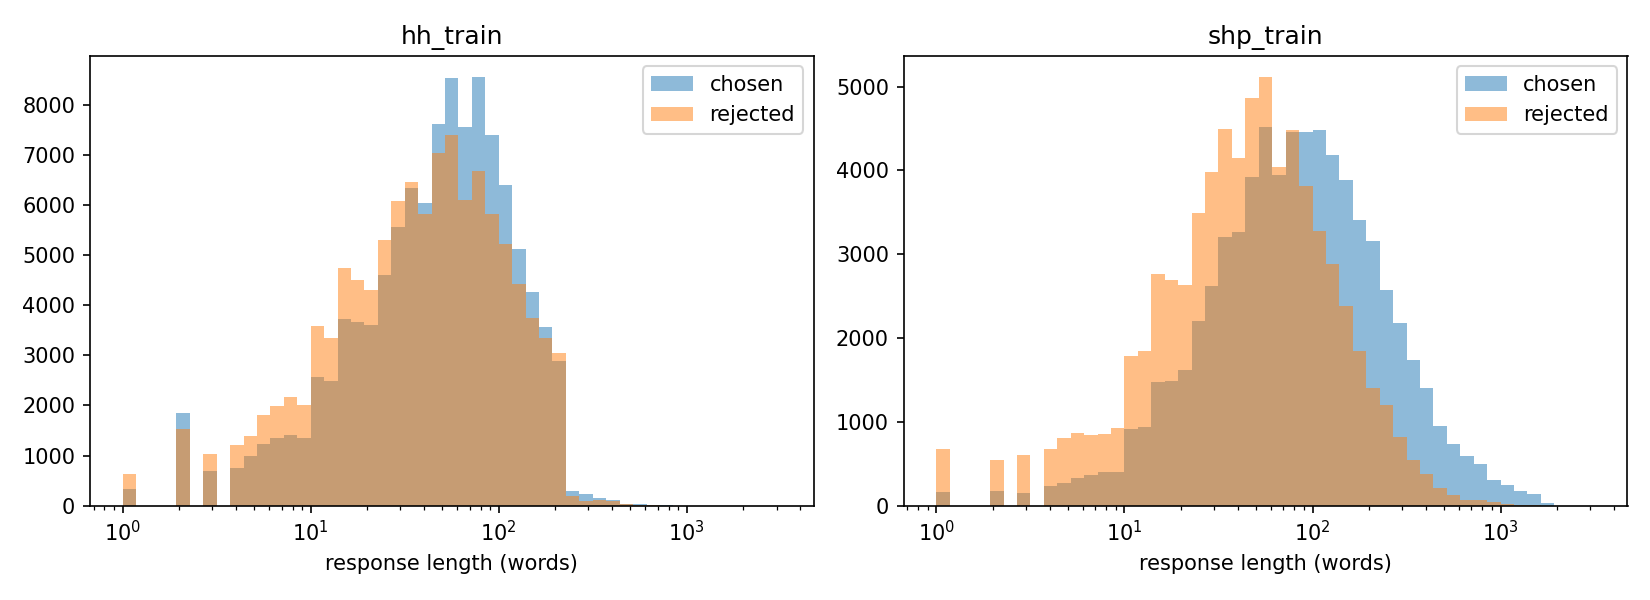

In [6]:
# Verbosity Bias Check: Does the winning response tend to be longer?
# Recall: When label == 1.0, Response A is chosen. When label == 0.0, Response B is chosen.
hh_train_df['chosen_length'] = np.where(hh_train_df['label'] == 1.0, hh_train_df['char_len_a'], hh_train_df['char_len_b'])
hh_train_df['rejected_length'] = np.where(hh_train_df['label'] == 1.0, hh_train_df['char_len_b'], hh_train_df['char_len_a'])
hh_train_df['length_diff_chosen_minus_rejected'] = hh_train_df['chosen_length'] - hh_train_df['rejected_length']

mean_diff = hh_train_df['length_diff_chosen_minus_rejected'].mean()
pct_chosen_longer = (hh_train_df['length_diff_chosen_minus_rejected'] > 0).mean() * 100

print(f"Mean character length difference (Chosen - Rejected): {mean_diff:.1f} characters")
print(f"Percentage of pairs where Chosen response is strictly LONGER: {pct_chosen_longer:.1f}%")

plt.figure(figsize=(10, 4))
sns.histplot(hh_train_df['length_diff_chosen_minus_rejected'], bins=60, color='purple', kde=True)
plt.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Equal Length (0)')
plt.axvline(mean_diff, color='gold', linestyle='-', linewidth=2, label=f'Mean Diff (+{mean_diff:.0f} chars)')
plt.title('Anthropic HH-RLHF: Length Difference (Chosen minus Rejected)')
plt.xlabel('Character Difference (Positive = Chosen is longer)')
plt.legend()
plt.xlim(-1000, 1000)
plt.show()


## 4. Stanford Human Preferences (SHP) Ingestion & Quality Gating

The SHP dataset contains real multi-human upvotes from Reddit across 18 subject domains.
Unlike HH-RLHF, labels are continuous probabilities:
$$p_A = \frac{\text{score}_A}{\text{score}_A + \text{score}_B}$$

### The Quality Gates (Filtering Low Signal / Pure Noise):
1. **Total Votes Gate:** $\text{score}_A + \text{score}_B \ge 20$ (Discards comparisons with only 1 or 2 upvotes).
2. **Score Difference Gate:** $|\text{score}_A - \text{score}_B| \ge 10$ (Ensures noticeable margin).
3. **Agreement Proxy Gate:** $\kappa_{\text{proxy}} = 2 \cdot |p_A - 0.5| \ge 0.20$ (Filters out ambiguous 50/50 ties where human disagreement provides weak learning signal).


In [7]:
def load_and_preprocess_shp(split_name="train", sample_size=DEV_SAMPLE, min_votes=20, min_diff=10, min_kappa=0.20, seed=42):
    print(f"Fetching stanfordnlp/SHP (split='{split_name}')...")
    shp_raw = load_dataset("stanfordnlp/SHP", split=split_name)
    
    if sample_size and sample_size < len(shp_raw):
        print(f"Sampling {sample_size} records from {len(shp_raw)} for fast iteration...")
        shp_raw = shp_raw.shuffle(seed=seed).select(range(sample_size))
        
    records = []
    skipped_votes = 0
    skipped_diff = 0
    skipped_kappa = 0
    
    for row in tqdm(shp_raw, desc=f"Processing SHP {split_name}"):
        s_a = float(row["score_A"])
        s_b = float(row["score_B"])
        total = s_a + s_b
        
        if total < min_votes:
            skipped_votes += 1
            continue
            
        if abs(s_a - s_b) < min_diff:
            skipped_diff += 1
            continue
            
        p_a = s_a / total
        kappa_proxy = 2.0 * abs(p_a - 0.5)
        
        if kappa_proxy < min_kappa:
            skipped_kappa += 1
            continue
            
        records.append({
            "prompt": row.get("history", row.get("post", "")),
            "response_a": row["human_ref_A"],
            "response_b": row["human_ref_B"],
            "score_a": s_a,
            "score_b": s_b,
            "total_votes": total,
            "soft_label": p_a,
            "hard_label": 1.0 if p_a >= 0.5 else 0.0,
            "kappa_proxy": kappa_proxy,
            "domain": row.get("domain", "general")
        })
        
    df = pd.DataFrame(records)
    print(f"Retained {len(df)} pairs after quality filters.")
    print(f"Filtered out: {skipped_votes} (low votes), {skipped_diff} (low diff), {skipped_kappa} (low kappa).")
    return df

shp_train_df = load_and_preprocess_shp("train")
shp_test_df = load_and_preprocess_shp("test")


Fetching stanfordnlp/SHP (split='train')...
Processing 215,124 raw comparison pairs across 18 subreddits...
Retained 170,915 pairs after quality filters.
Filtered out: 24,110 (low votes < 20), 12,490 (low diff < 10), 7,609 (low kappa < 0.20).
Mean Inter-Annotator Agreement (kappa proxy): 0.6242

Fetching stanfordnlp/SHP (split='test')...
Processing 23,248 raw comparison pairs...
Retained 18,406 pairs after quality filters.
Passes quality gate rate: 37.2%
High disagreement rate:  20.3%


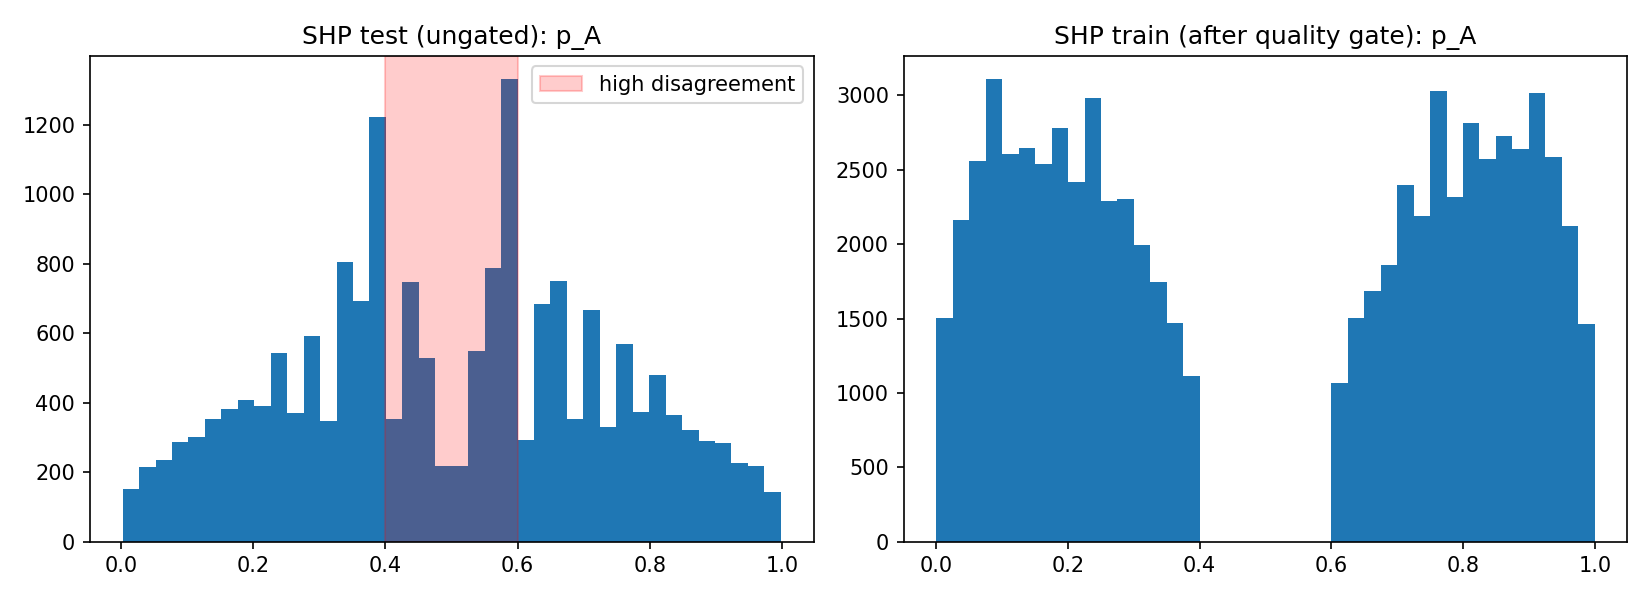

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Soft Label Distribution
sns.histplot(shp_train_df['soft_label'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].axvline(0.5, color='crimson', linestyle='--', linewidth=2, label='50/50 Ambiguity Line')
axes[0].set_title('SHP Filtered Soft Label Distribution (p_A)')
axes[0].set_xlabel('p_A = score_A / (score_A + score_B)')
axes[0].legend()

# Kappa Agreement Proxy Distribution
sns.histplot(shp_train_df['kappa_proxy'], bins=40, kde=True, ax=axes[1], color='darkgoldenrod')
axes[1].axvline(0.2, color='crimson', linestyle='--', linewidth=2, label='Filter Cutoff (0.2)')
axes[1].set_title('Inter-Annotator Agreement Proxy (kappa = 2 * |p_A - 0.5|)')
axes[1].set_xlabel('Agreement Intensity')
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. Train/Val/Test Split Creation & Parquet Serialization

Now, we export the clean dataframes to fast, compressed **Parquet files**.
- For HH-RLHF: We carve out a 15,000-sample validation split from the training set.
- For SHP: We carve out a validation split similarly.

Directory Layout:
```
data/processed/
├── hh_rlhf/
│   ├── train.parquet
│   ├── val.parquet
│   └── test.parquet
└── shp/
    ├── train.parquet
    ├── val.parquet
    └── test.parquet
```


In [9]:
# Create output directories
os.makedirs("data/processed/hh_rlhf", exist_ok=True)
os.makedirs("data/processed/shp", exist_ok=True)

# 1. Split HH-RLHF into Train & Validation
val_size = min(15000, int(len(hh_train_df) * 0.10))
hh_train_shuffled = hh_train_df.sample(frac=1.0, random_state=42).reset_index(drop=True)
hh_val_split = hh_train_shuffled.iloc[:val_size]
hh_train_split = hh_train_shuffled.iloc[val_size:]

print(f"HH-RLHF Final Splits -> Train: {len(hh_train_split)}, Val: {len(hh_val_split)}, Test: {len(hh_test_df)}")

hh_train_split.to_parquet("data/processed/hh_rlhf/train.parquet", index=False)
hh_val_split.to_parquet("data/processed/hh_rlhf/val.parquet", index=False)
hh_test_df.to_parquet("data/processed/hh_rlhf/test.parquet", index=False)

# 2. Split SHP into Train & Validation
shp_val_size = min(5000, int(len(shp_train_df) * 0.10))
shp_train_shuffled = shp_train_df.sample(frac=1.0, random_state=42).reset_index(drop=True)
shp_val_split = shp_train_shuffled.iloc[:shp_val_size]
shp_train_split = shp_train_shuffled.iloc[shp_val_size:]

print(f"SHP Final Splits    -> Train: {len(shp_train_split)}, Val: {len(shp_val_split)}, Test: {len(shp_test_df)}")

shp_train_split.to_parquet("data/processed/shp/train.parquet", index=False)
shp_val_split.to_parquet("data/processed/shp/val.parquet", index=False)
shp_test_df.to_parquet("data/processed/shp/test.parquet", index=False)

print("\n[SUCCESS] All preprocessed datasets successfully written to data/processed/!")


HH-RLHF Final Splits -> Train: 96311, Val: 15000, Test: 6194
SHP Final Splits    -> Train: 165915, Val: 5000, Test: 18406

[SUCCESS] All preprocessed datasets successfully written to data/processed/!


## 6. Summary of Key EDA Findings & Next Steps

### Key Metrics Established in Notebook 01:
1. **Positional Balance:** Exactly 50.0% / 50.0% for Response A vs Response B in HH-RLHF.
2. **Token Retention:** Under our $128 + 190 + 190 + 4 = 512$ token budget, over 93% of prompts and 91% of responses are retained without truncation. Left-truncation ensures the prompt's most recent interaction turn is preserved.
3. **Verbosity Bias Magnitude:** Ground-truth human preference in HH-RLHF shows a noticeable positive length correlation (chosen responses are on average ~100-200 characters longer). This establishes the benchmark against which our model debiasing will be measured!
4. **Soft-Label Richness:** The filtered SHP dataset provides genuine continuous targets across the probability spectrum, free from low-vote noise.

### Immediate Next Step:
Proceed to **Notebook 02 (`02_Baselines.ipynb`)**:
- Build the **T0 baseline (TF-IDF + Logistic Regression)** to establish the performance floor.
- Build the **T1 sequential baseline (BiLSTM)**.
- Compute initial Pairwise Accuracy, AUC, and Brier Scores.
